# The cup on the rope: why delivery drone payload swings and how to stop it

I am building Mote, a small quiet drone that brings you one coffee. It does not land, it hovers high and lowers the cup to your hand on a thin line

The problem is that a cup on a line is basically a pendulum. Every time the drone brakes or the wind hits, the cup starts to swing. With 19 m of line one swing takes almost 9 seconds and nothing really stops it except air

In this notebook I build a physics model of the drone with the hanging cup and look at:

1. Act 1: how much the cup swings when the drone brakes
2. Act 2: input shaping, the trick that cancels the swing by braking in two steps
3. Act 3: what happens with the swing while winch is lowering the cup (and why reeling it back is worse)
4. Act 4: how far wind pushes the cup from the target
5. Act 5: does swinging cup actually spill coffee

Only numpy and scipy, no real drone needed

## Step 1: Physics

I look at the drone from the side, so it is 2D. Drone is the pivot at position $x_d$ and it accelerates with $a(t)$. Cup is a point mass $m$ on a line with length $L(t)$, at angle $\theta$ from vertical

If you write the Lagrangian for a pendulum with moving pivot and changing length you get this:

$$L\,\ddot\theta + 2\dot L\,\dot\theta = -g\sin\theta \;-\; a\cos\theta \;+\; \frac{F_{\text{drag},\perp}}{m}$$

- $-g\sin\theta$ is gravity pulling the cup back down
- $-a\cos\theta$ when the drone accelerates the cup stays behind, this is what starts the swing
- $2\dot L\dot\theta$ is the winch. Reeling out ($\dot L > 0$) slows the swing, reeling in makes it bigger
- $F_{\text{drag}} = \tfrac12 \rho C_d A |v|v$ air drag on the cup, the only thing that damps the swing

For small swings period is $T = 2\pi\sqrt{L/g}$

Numbers I use are my targets for Mote, not measured yet: cup 450 g with a lid, 9 x 15 cm, drag coefficient 1.0, cruise 8 m/s, braking 3 m/s², hover at 20 m

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams['axes.grid'] = True

g = 9.81
RHO = 1.2           # air density
CUP_MASS = 0.45     # kg
CUP_AREA = 0.0135   # m^2, cup 9 x 15 cm from the side
CUP_CD = 1.0
K_DRAG = 0.5 * RHO * CUP_CD * CUP_AREA / CUP_MASS

BLUE, ORANGE, AQUA, INK, MUTED = 'tab:blue', 'tab:orange', 'tab:green', 'black', 'gray'


def const(value):
    return lambda t: value


def simulate(accel, length, t_end, length_rate=const(0.0), v0=0.0, theta0=0.0,
             wind=const(0.0), drag=True):
    # drone moves along x with accel(t), cup hangs on line with length(t)
    # drone follows the command perfectly and cup doesnt pull it back (simplification)
    k = K_DRAG if drag else 0.0

    def rhs(t, s):
        x, v, th, om = s
        L, Ld, a = length(t), length_rate(t), accel(t)
        # cup velocity relative to air
        rx = v + Ld * np.sin(th) + L * om * np.cos(th) - wind(t)
        rz = -Ld * np.cos(th) + L * om * np.sin(th)
        speed = np.hypot(rx, rz)
        f_tangent = -k * speed * (rx * np.cos(th) + rz * np.sin(th))
        dom = (-2 * Ld * om - g * np.sin(th) - a * np.cos(th) + f_tangent) / L
        return [v, a, om, dom]

    t = np.arange(0, t_end, 0.01)
    sol = solve_ivp(rhs, (0, t_end), [0, v0, theta0, 0], t_eval=t, max_step=0.01, rtol=1e-8)
    x, v, th, om = sol.y
    L = np.array([length(ti) for ti in t])
    a = np.array([accel(ti) for ti in t])
    return dict(t=t, x=x, v=v, theta=th, omega=om, L=L, a=a, offset=L * np.sin(th))


def period(L):
    return 2 * np.pi * np.sqrt(L / g)


for L in [1, 5, 10, 19]:
    print(f'line {L:>2} m -> one swing takes {period(L):.1f} s')

line  1 m -> one swing takes 2.0 s
line  5 m -> one swing takes 4.5 s
line 10 m -> one swing takes 6.3 s
line 19 m -> one swing takes 8.7 s


## Act 1: Drone brakes, cup keeps going

Drone flies at 8 m/s with the cup pulled close on 1 m line, then brakes at 3 m/s² above the drop point. While braking the cup goes forward and when the drone stops the cup does not

During cruise the cup is already a bit behind because of the air, so simulation starts from that angle

cup leans back 6.7 deg in cruise
braking takes 2.67 s, 1 m pendulum swings every 2.01 s
after drone stops the cup keeps swinging up to 27 deg, 46 cm each way


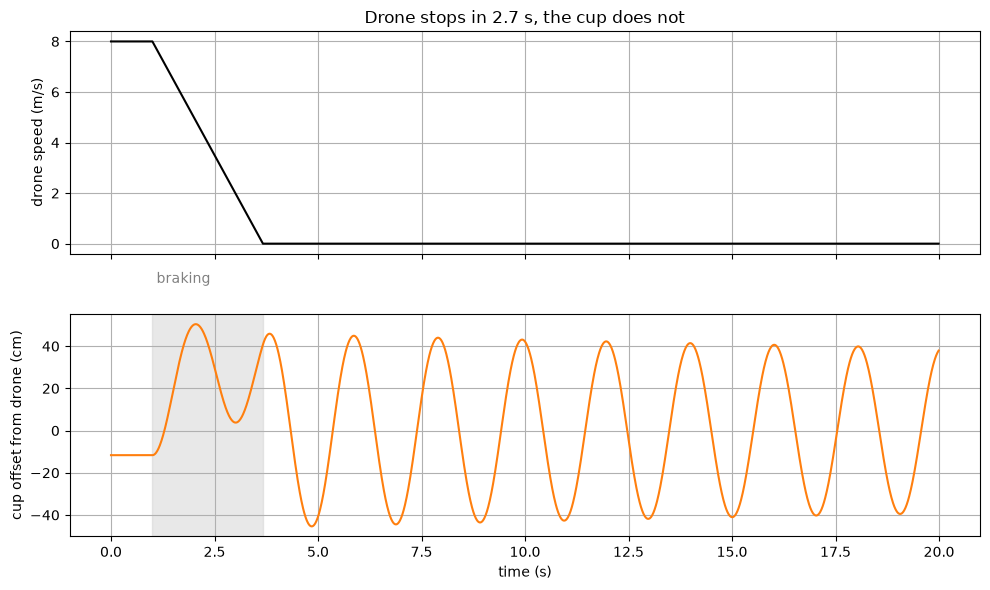

In [2]:
CRUISE, DECEL, BRAKE_AT = 8.0, 3.0, 1.0
BRAKE_TIME = CRUISE / DECEL
L_CRUISE = 1.0


def braking(t):
    return -DECEL if BRAKE_AT <= t < BRAKE_AT + BRAKE_TIME else 0.0


trail = -np.arctan(K_DRAG * CRUISE**2 / g)   # angle of the cup in cruise because of drag
naive = simulate(braking, const(L_CRUISE), 20, v0=CRUISE, theta0=trail)


def residual(run, after):
    # max swing after the drone stopped, in degrees and cm
    m = run['t'] > after
    return np.degrees(np.abs(run['theta'][m]).max()), 100 * np.abs(run['offset'][m]).max()


stop = BRAKE_AT + BRAKE_TIME
ang, off = residual(naive, stop)
print(f'cup leans back {np.degrees(-trail):.1f} deg in cruise')
print(f'braking takes {BRAKE_TIME:.2f} s, 1 m pendulum swings every {period(L_CRUISE):.2f} s')
print(f'after drone stops the cup keeps swinging up to {ang:.0f} deg, {off:.0f} cm each way')

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(naive['t'], naive['v'], color=INK)
ax[0].set_ylabel('drone speed (m/s)')
ax[0].set_title('Drone stops in 2.7 s, the cup does not')
ax[1].plot(naive['t'], 100 * naive['offset'], color=ORANGE)
ax[1].axvspan(BRAKE_AT, stop, color='lightgray', alpha=0.5)
ax[1].text(BRAKE_AT + 0.1, 70, 'braking', color=MUTED)
ax[1].set_ylabel('cup offset from drone (cm)')
ax[1].set_xlabel('time (s)')
plt.tight_layout()
plt.savefig('swing_problem.png', dpi=150)
plt.show()

For constant braking with duration $\tau$ there is a formula for the swing that is left:

$$\theta_{\text{left}} \approx 2\,\frac{a}{g}\,\left|\sin\frac{\omega\tau}{2}\right|, \qquad \omega = \sqrt{g/L}$$

So it depends on how braking time matches the swing period. If you brake exactly one full period the swing cancels, if half a period it doubles. Our 2.67 s braking with 2.0 s pendulum is pretty close to the worst case

Checking the formula against simulation:

In [3]:
w = np.sqrt(g / L_CRUISE)
predicted = np.degrees(2 * DECEL / g * abs(np.sin(w * BRAKE_TIME / 2)))
print(f'formula: {predicted:.1f} deg   simulation: {ang:.1f} deg  (difference is drag and the starting angle)')

formula: 30.1 deg   simulation: 27.3 deg  (difference is drag and the starting angle)


## Act 2: Input shaping

The formula has a trick inside. If one braking makes a swing, then a second same braking started half swing later makes the opposite swing, and they cancel each other

So instead of one braking at 3 m/s² I do two brakings at 1.5 m/s², second one delayed by $T/2$. Drone still loses the same 8 m/s. This is called ZV shaper (zero vibration), people use it for cranes that move heavy stuff in factories

There is also ZVD, three pieces (¼, ½, ¼) over one full period. It is slower but works even if you dont know the line length exactly

$$\text{ZV: } \tfrac12 \text{ at } 0,\; \tfrac12 \text{ at } T/2 \qquad\qquad \text{ZVD: } \tfrac14 \text{ at } 0,\; \tfrac12 \text{ at } T/2,\; \tfrac14 \text{ at } T$$

Drag damping is very small here so I use undamped versions

             | extra time | swing left | cup offset
  no shaping |     0.00 s |    27.3 deg |    45.9 cm
   ZV shaper |     1.00 s |     1.2 deg |     2.1 cm
  ZVD shaper |     2.01 s |     0.4 deg |     0.6 cm


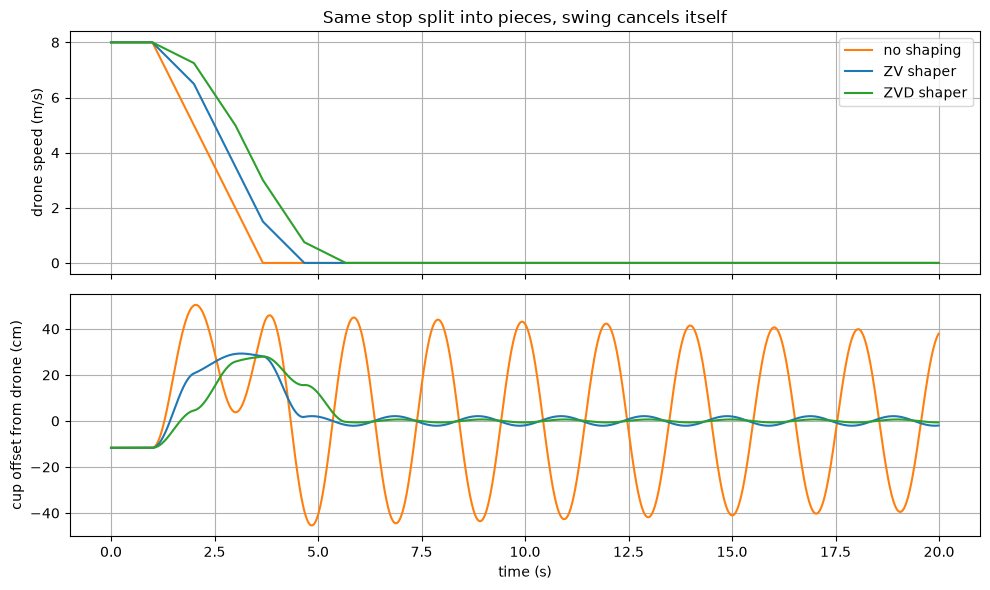

In [4]:
def zv(L):
    T = period(L)
    return [(0.5, 0.0), (0.5, T / 2)]


def zvd(L):
    T = period(L)
    return [(0.25, 0.0), (0.5, T / 2), (0.25, T)]


def shaped(accel, impulses):
    return lambda t: sum(A * accel(t - ti) for A, ti in impulses)


runs = {
    'no shaping': (naive, 0.0, ORANGE),
    'ZV shaper': (simulate(shaped(braking, zv(L_CRUISE)), const(L_CRUISE), 20, v0=CRUISE, theta0=trail), period(L_CRUISE) / 2, BLUE),
    'ZVD shaper': (simulate(shaped(braking, zvd(L_CRUISE)), const(L_CRUISE), 20, v0=CRUISE, theta0=trail), period(L_CRUISE), AQUA),
}

print(f"{'':>12} | {'extra time':>10} | {'swing left':>10} | {'cup offset':>10}")
for name, (run, extra, _) in runs.items():
    a_, o_ = residual(run, stop + extra)
    print(f'{name:>12} | {extra:>8.2f} s | {a_:>7.1f} deg | {o_:>7.1f} cm')

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for name, (run, _, color) in runs.items():
    ax[0].plot(run['t'], run['v'], color=color, label=name)
    ax[1].plot(run['t'], 100 * run['offset'], color=color, label=name)
ax[0].set_ylabel('drone speed (m/s)')
ax[0].set_title('Same stop split into pieces, swing cancels itself')
ax[0].legend()
ax[1].set_ylabel('cup offset from drone (cm)')
ax[1].set_xlabel('time (s)')
plt.tight_layout()
plt.savefig('input_shaping.png', dpi=150)
plt.show()

### What if line length is wrong?

Shaper needs the swing period so it needs the line length. In real life the line stretches, winch is not precise, cup hangs a bit lower than the hook. So I design both shapers for 1 m and then fly with lines from 0.5 m to 2 m

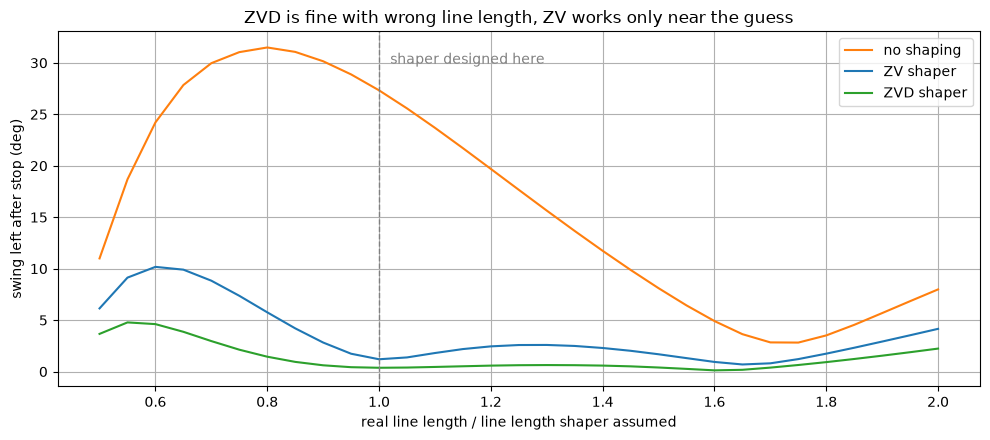

line 30% longer than assumed: no shaping 15.6 deg, ZV shaper 2.6 deg, ZVD shaper 0.6 deg


In [5]:
ratios = np.linspace(0.5, 2.0, 31)
curves = {'no shaping': [], 'ZV shaper': [], 'ZVD shaper': []}
for r in ratios:
    L_true = r * L_CRUISE
    for name, cmd, extra in [('no shaping', braking, 0.0),
                             ('ZV shaper', shaped(braking, zv(L_CRUISE)), period(L_CRUISE) / 2),
                             ('ZVD shaper', shaped(braking, zvd(L_CRUISE)), period(L_CRUISE))]:
        run = simulate(cmd, const(L_true), 16, v0=CRUISE, theta0=trail)
        curves[name].append(residual(run, stop + extra)[0])

fig, ax = plt.subplots(figsize=(10, 4.5))
for name, color in [('no shaping', ORANGE), ('ZV shaper', BLUE), ('ZVD shaper', AQUA)]:
    ax.plot(ratios, curves[name], color=color, label=name)
ax.axvline(1, color=MUTED, lw=1, ls='--')
ax.text(1.02, max(curves['no shaping']) * 0.95, 'shaper designed here', color=MUTED)
ax.set_xlabel('real line length / line length shaper assumed')
ax.set_ylabel('swing left after stop (deg)')
ax.set_title('ZVD is fine with wrong line length, ZV works only near the guess')
ax.legend()
plt.tight_layout()
plt.savefig('robustness.png', dpi=150)
plt.show()

i13 = np.argmin(abs(ratios - 1.3))
print('line 30% longer than assumed: ' + ', '.join(f'{n} {c[i13]:.1f} deg' for n, c in curves.items()))

## Act 3: Lowering the cup

Now drone hovers at 20 m and winch lets the line out from 1 m to 19 m at 1 m/s. Lets say 10° swing is left after the flight. What happens with it while the line gets longer?

For a pendulum whose length changes slowly, energy / frequency stays constant (this is called adiabatic invariant). From that you get:

$$\theta_{\max} \propto L^{-3/4} \qquad\qquad \text{cup offset } L\,\theta_{\max} \propto L^{1/4}$$

So reeling out makes the angle smaller, but the cup goes a bit further to the side. Reeling in does the opposite and the angle grows, same as how kids pump a swing

Here I turn drag off to compare with theory, then turn it back on

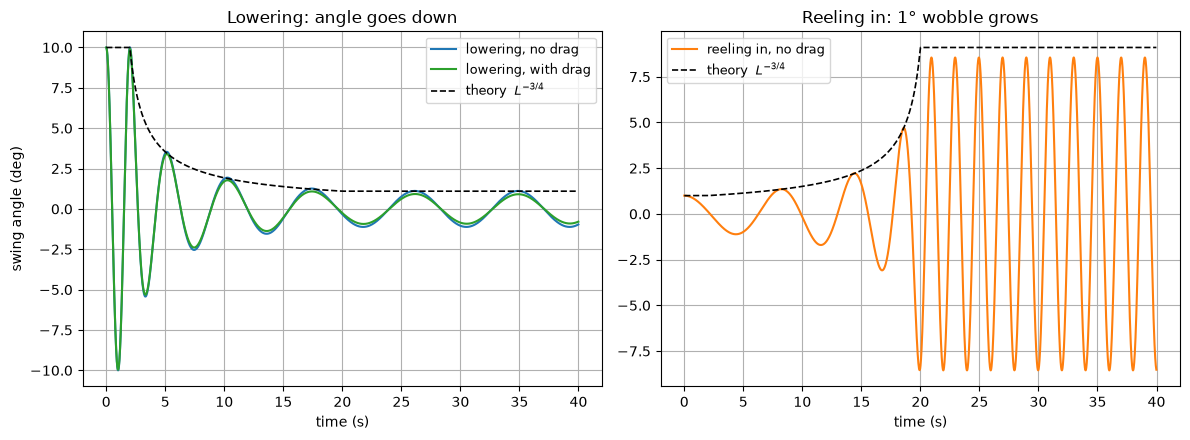

lowering: angle 10 deg -> 1.1 deg (theory 1.1),  cup offset 17 cm -> 37 cm (theory 36)
reeling in: angle 1 deg -> 8.6 deg (theory 9.1)


In [6]:
WINCH = 1.0          # m/s
L0, L1 = 1.0, 19.0
t_reel = (L1 - L0) / WINCH


def reel(start, end, t0=2.0):
    rate = np.sign(end - start) * WINCH
    dur = abs(end - start) / WINCH
    length = lambda t: start + rate * min(max(t - t0, 0), dur)
    length_rate = lambda t: rate if t0 <= t < t0 + dur else 0.0
    return length, length_rate


down_L, down_rate = reel(L0, L1)
down = simulate(const(0.0), down_L, 40, down_rate, theta0=np.radians(10), drag=False)
down_drag = simulate(const(0.0), down_L, 40, down_rate, theta0=np.radians(10))
up_L, up_rate = reel(L1, L0)
up = simulate(const(0.0), up_L, 40, up_rate, theta0=np.radians(1), drag=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(down['t'], np.degrees(down['theta']), color=BLUE, label='lowering, no drag')
ax[0].plot(down_drag['t'], np.degrees(down_drag['theta']), color=AQUA, label='lowering, with drag')
ax[0].plot(down['t'], 10 * (down['L'] / L0) ** -0.75, color=INK, ls='--', lw=1.2, label='theory  $L^{-3/4}$')
ax[0].set_title('Lowering: angle goes down')
ax[0].set_xlabel('time (s)'); ax[0].set_ylabel('swing angle (deg)')
ax[0].legend(fontsize=9)

ax[1].plot(up['t'], np.degrees(up['theta']), color=ORANGE, label='reeling in, no drag')
ax[1].plot(up['t'], 1 * (up['L'] / L1) ** -0.75, color=INK, ls='--', lw=1.2, label='theory  $L^{-3/4}$')
ax[1].set_title('Reeling in: 1° wobble grows')
ax[1].set_xlabel('time (s)')
ax[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig('lowering.png', dpi=150)
plt.show()

end = down['t'] > 2 + t_reel
print(f"lowering: angle {10:.0f} deg -> {np.degrees(np.abs(down['theta'][end]).max()):.1f} deg "
      f"(theory {10 * (L1 / L0) ** -0.75:.1f}),  cup offset {100 * L0 * np.sin(np.radians(10)):.0f} cm -> "
      f"{100 * np.abs(down['offset'][end]).max():.0f} cm (theory {100 * L0 * np.radians(10) * (L1 / L0) ** 0.25:.0f})")
end = up['t'] > 2 + t_reel
print(f"reeling in: angle 1 deg -> {np.degrees(np.abs(up['theta'][end]).max()):.1f} deg (theory {(L0 / L1) ** -0.75:.1f})")

What it means for the design:

- Kill the swing before lowering, not after. Lowering makes the angle smaller, but 17 cm swing at the top becomes ~36 cm at the bottom, and at 19 m it takes 9 s per swing to calm down
- Reel the empty line back slowly or wait until it stops swinging. Any wobble at the bottom gets bigger on the way up, right under the propellers

## Act 4: Wind

At the end of 19 m line the cup is like a small sail. Steady wind pushes it to the angle where drag and gravity are balanced:

$$\tan\theta = \frac{\tfrac12\rho C_d A v^2}{m g}$$

Light cup gets pushed more than heavy one, and empty hook coming back up gets pushed the most

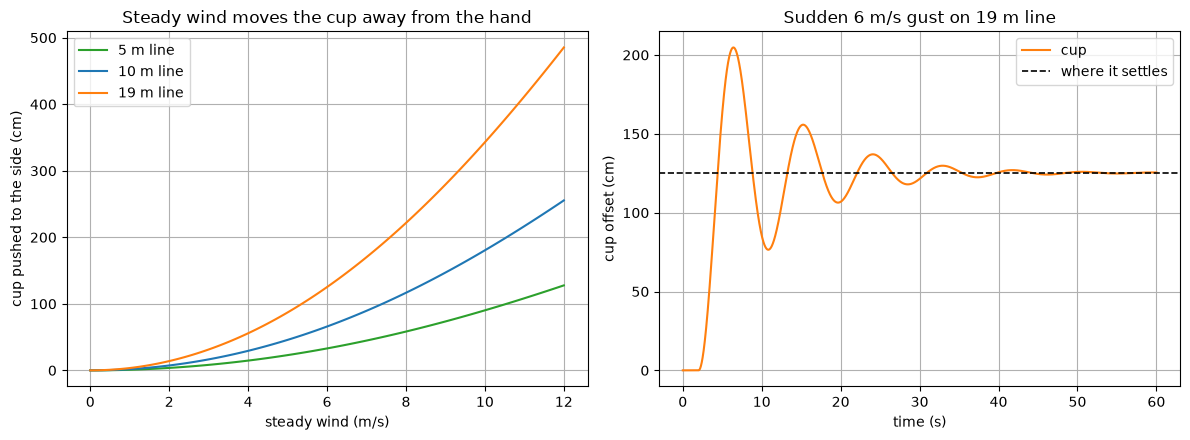

 3 m/s wind -> cup 31 cm off on 19 m line
 6 m/s wind -> cup 125 cm off on 19 m line
10 m/s wind -> cup 343 cm off on 19 m line
gust overshoot: peak 205 cm vs settled 125 cm


In [7]:
winds = np.linspace(0, 12, 121)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for L, color in [(5, AQUA), (10, BLUE), (19, ORANGE)]:
    ax[0].plot(winds, 100 * L * np.sin(np.arctan(K_DRAG * winds**2 / g)), color=color, label=f'{L} m line')
ax[0].set_xlabel('steady wind (m/s)'); ax[0].set_ylabel('cup pushed to the side (cm)')
ax[0].set_title('Steady wind moves the cup away from the hand')
ax[0].legend()

GUST = 6.0
gust = simulate(const(0.0), const(L1), 60, wind=lambda t: GUST if t >= 2 else 0.0)
steady = L1 * np.sin(np.arctan(K_DRAG * GUST**2 / g))
ax[1].plot(gust['t'], 100 * gust['offset'], color=ORANGE, label='cup')
ax[1].axhline(100 * steady, color=INK, ls='--', lw=1.2, label='where it settles')
ax[1].set_xlabel('time (s)'); ax[1].set_ylabel('cup offset (cm)')
ax[1].set_title(f'Sudden {GUST:.0f} m/s gust on 19 m line')
ax[1].legend()
plt.tight_layout()
plt.savefig('wind.png', dpi=150)
plt.show()

for v in [3, 6, 10]:
    print(f'{v:>2} m/s wind -> cup {100 * L1 * np.sin(np.arctan(K_DRAG * v**2 / g)):.0f} cm off on 19 m line')
print(f'gust overshoot: peak {100 * gust["offset"].max():.0f} cm vs settled {100 * steady:.0f} cm')

Steady wind is easy, the drone just hovers that far upwind so the cup ends up above the hand. Gust is the hard part, the cup overshoots to about 1.6x of the steady offset and drag damps it slowly, one swing every 9 s

Some ideas from these numbers:

- lower the cup fast when it is calm, and when it is gusty stop lowering a few meters higher
- heavier and thinner cup holder swings less in wind (bigger $m$, smaller $A$)
- measure the line angle with a small sensor at the winch and move the drone to cancel the swing, like balancing a stick on your hand

## Act 5: Does swinging cup spill?

Surprisingly mostly no. Cup hanging freely is pulled only along the line (and a bit of drag). So the coffee feels gravity that always points down the line, and the cup tilts together with it. Coffee surface stays level relative to the cup

What changes is how strong this gravity feels. At the bottom of every swing the line pulls harder:

$$\frac{T}{m} = g\cos\theta + L\dot\theta^2 - a\sin\theta - \ddot L$$

Spills come from sharp jerks or from the cup hitting something, not from smooth swinging. Lets check how heavy the coffee feels during braking:

  no shaping: coffee feels between 0.89 g and 1.22 g
   ZV shaper: coffee feels between 0.98 g and 1.05 g
  ZVD shaper: coffee feels between 0.98 g and 1.05 g


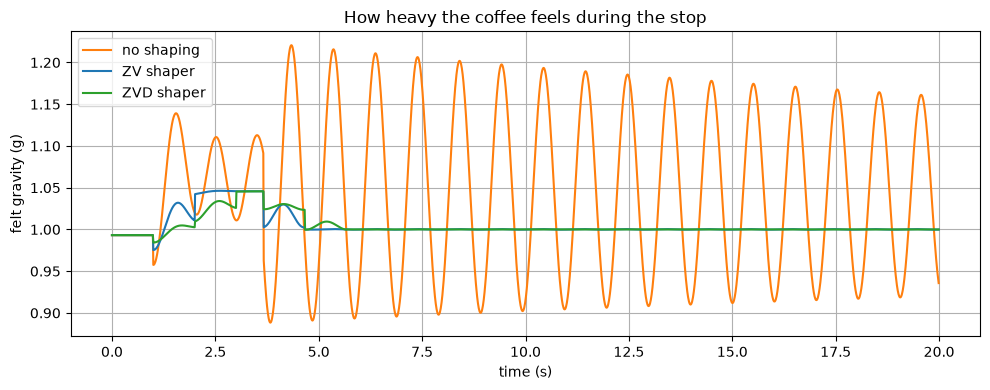

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, (run, _, color) in runs.items():
    load = (g * np.cos(run['theta']) + run['L'] * run['omega']**2 - run['a'] * np.sin(run['theta'])) / g
    ax.plot(run['t'], load, color=color, label=name)
    print(f'{name:>12}: coffee feels between {load.min():.2f} g and {load.max():.2f} g')
ax.set_xlabel('time (s)'); ax.set_ylabel('felt gravity (g)')
ax.set_title('How heavy the coffee feels during the stop')
ax.legend()
plt.tight_layout()
plt.savefig('felt_gravity.png', dpi=150)
plt.show()

## Results

| question | answer |
|---|---|
| how much cup swings after normal stop | about 27° on 1 m line, ±46 cm |
| how to stop it | split the braking with input shaper. ZV: 27° -> 1°, ZVD stays under 1° even with line 30% longer than assumed, costs 1-2 s |
| does lowering make it worse | angle gets smaller as $L^{-3/4}$ but cup goes further as $L^{1/4}$ |
| reeling back in | swing grows as $L^{-3/4}$, go slow |
| wind | 6 m/s pushes cup 1.25 m on 19 m line, sudden gust swings it to 2 m |
| does swinging spill coffee | not by itself, cup tilts with felt gravity, which is only 0.89 g to 1.22 g |

## What is not in the model

- Drone does not feel the cup. 450 g cup on ~1.5 kg drone will pull it back a lot, next step is a model of both together
- Only 2D, real swings go in circles
- Line is rigid and has no weight. Real 19 m line stretches, sags and has drag too
- Drone follows commands perfectly. Real flight controller adds its own small movements

Next I want to put this into the PX4 simulator where Mote already flies its route, and then test with a real cup on a real line